In [14]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 1/29/2022
# version ='1.0'

# Demo: Further Experiments on Solving $l_1$-norm approximation by Barrier Method

In book-convex-2004, the barrier method was used to solve the $l_1$ norm approximation problem

$$
\begin{array}{rl}
\text{minimize} & \parallel Ax-b \parallel_1
\end{array}
$$
where $A\in R^{m\times n}$. The $l_1$ norm approximation problem can be expressed as an LP by introducing auxiliary variables $y\in R^m$. That is

$$
\begin{array}{rcl}
\text{minimize} & c^Tz \\
\text{subject to} & F z \preceq d \\                                                                
\end{array}
$$

where
$$
\begin{array}{rclcl}
F & = & \left[\begin{array}{cc}
A & -I \\
-A & -I \\
\end{array} \right] & \doteq & \left[\begin{array}{c}
f_1^T \\
f_2^T \\
... \\
f_{2m}^T \\
\end{array} \right] \\
z & = & \left[\begin{array}{c}
x \\
y \\
\end{array} \right] \\
c & = & \left[\begin{array}{c}
\mathbf{0}_n \\
\mathbf{1}_1 \\
\end{array} \right] \\
y & \in & R^m \\
d & = & \left[\begin{array}{c}
b \\
-b \\
\end{array} \right] \\
\end{array} 
$$

Then, the centering problem in the barrier method is

$$
\begin{array}{rl}
\text{minimize} & f(z)=tc^Tz-\displaystyle{\sum_{i=1}^{2m} log(d_i-f_i^Tz)}
\end{array}
$$
Its gradient is
$$
\begin{array}{rcl}
\nabla f(z) & = & tc + \displaystyle{\sum_{i=1}^{2m} f_i\dfrac{1}{(d_i-f_i^Tz)}} \\
& = & tc + F^T \left[\begin{array}{c}
1/(d_1-f_1^Tz) \\
... \\
1/(d_{2m}-f_{2m}^Tz) \\
\end{array} \right] \\
& = & tc + \left[\begin{array}{cc}
A^T & -A^T \\
-I & -I \\
\end{array} \right] \left[\begin{array}{c}
1/(b-Ax+y) \\
1/(-b+Ax+y) \\
\end{array} \right] \\
& = & \left[\begin{array}{c}
A^Tg_1 \\
g_2 \\
\end{array} \right]
\end{array}
$$
where 
$$
\begin{array}{rcl}
g_1 & = & diag(b-Ax+y)^{-1}\mathbf{1}-diag(-b+Ax+y)^{-1}\mathbf{1} \\
g_2 & = & t\mathbf{1} - diag(b-Ax+y)^{-1}\mathbf{1}-diag(-b+Ax+y)^{-1}\mathbf{1} \\
\end{array}
$$

Its hessian is
$$
\begin{array}{rcl}
\nabla^2 f(z) & = & \displaystyle{\sum_{i=1}^{2m}}\dfrac{f_if_i^T}{(d_i-f_i^Tz)^2} \\
& = & F^T (diag(\dfrac{1}{(d-Fz)^2})) F \\
& = & \left[\begin{array}{cc}
A^T & -A^T \\
-I & -I \\
\end{array} \right] \left[\begin{array}{cc}
D_1 & 0 \\
0 & D_2 \\
\end{array} \right] \left[\begin{array}{cc}
A & -I \\
-A & -I \\
\end{array} \right] \\
\end{array}
$$
where
$$
\begin{array}{rcl}
D_1 & = & diag(b-Ax+y)^{-2} \\
D_2 & = & diag(-b+Ax+y)^{-2} \\
\end{array}
$$

So the Newton equation for the centering problem is
$$
\begin{array}{rcl}
\left[\begin{array}{cc}
A^T & -A^T \\
-I & -I \\
\end{array} \right] \left[\begin{array}{cc}
D_1 & 0 \\
0 & D_2 \\
\end{array} \right] \left[\begin{array}{cc}
A & -I \\
-A & -I \\
\end{array} \right] \left[\begin{array}{c}
\Delta x_{nt} \\
\Delta y_{nt} \\
\end{array} \right] & = & -\left[\begin{array}{c}
A^Tg_1 \\
g_2 \\
\end{array} \right] \\
\end{array}
$$

As discussed in section 11.8.2 in \cite{book-convex-2004}, block elimination can be used to accelerate the calculating, by first reducing this to 
$$
\begin{array}{rcl}
A^TDA\Delta x_{nt} & = & -A^Tg \\
\end{array}
$$
where 
$$
\begin{array}{rcl}
D & = & 4D_1D_2(D_1+D_2)^{-1} \\
 & = & diag(2 / (y^2+(b-Ax)^2))) \\
g & = & g_1+(D_1-D_2)(D_1+D_2)^{-1}g_2 \\
\end{array}
$$

And $\Delta y_{nt}$ can be obtained by
$$
\begin{array}{rcl}
\Delta y_{nt} & = & (D_1+D_2)^{-1}(-g_2+(D_1-D_2)A\Delta x_{nt}) \\
\end{array}
$$

The start point for the LP can be 
$$
\begin{array}{rcl}
z_0 & = & \left[\begin{array}{c}
0_n \\
abs(b)+1 \\
\end{array} \right]
\end{array}
$$

In [15]:
import time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator
from scipy.linalg import cho_factor, cho_solve

$f_0(x,y)=\sum_{i} y_i$

$\nabla f_0(x,y)=[0_{n}; 1_{m}]$

$\nabla f_0(x,y)=0_{(m+n)\times (m+n)}$

In [16]:
def my_f_0(x, y, t, A, b):
    """
    $f_0(x,y)=\sum_{i} y_i$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    return np.sum(y)


def my_f_0_feasible(x, y, t, A, b):
    return True


def my_gradient_f_0(x, y, t, A, b):
    """
    $\nabla f_0(x,y)=[0_{n}; 1_{m}]$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    m, n = A.shape
    _0n = np.zeros((n, 1))
    _1m = np.ones((m, 1))
    return np.block([[_0n], [_1m]])


def my_hessian_f_0(x, y, t, A, b):
    """
    $\nabla f_0(x,y)=0_{(m+n)\times (m+n)}$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    m, n = A.shape
    return np.zeros((n + m, n + m))

$\phi(z=[x,y])=\sum_i \log (d_i-f_i^Tz)$

$\nabla \phi(z=[x,y])=F^T(1/(d-Fz))$

$\nabla^2 \phi(z=[x,y])=F^T(diag(1/(d-Fz)^2))F$

In [17]:
def my_phi(x, y, t, A, b):
    """
    $\phi(z=[x,y])=\sum_i \log (d_i-f_i^Tz)$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    m, n = A.shape
    z = np.block([[x], [y]])
    Im = np.eye(m)
    F = np.block([[A, -Im], [-A, -Im]])
    d = np.block([[b], [-b]])
    return -1 * np.sum(np.log(d - F @ z))


def my_phi_feasible(x, y, t, A, b):
    m, n = A.shape
    z = np.block([[x], [y]])
    Im = np.eye(m)
    F = np.block([[A, -Im], [-A, -Im]])
    d = np.block([[b], [-b]])
    if np.all(F @ z <= d):
        return True
    else:
        return False


def my_gradient_phi(x, y, t, A, b):
    """
    $\nabla \phi(z=[x,y])=F^T(1/(d-Fz))$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    m, n = A.shape
    z = np.block([[x], [y]])
    Im = np.eye(m)
    F = np.block([[A, -Im], [-A, -Im]])
    d = np.block([[b], [-b]])
    g = F.T @ (1 / (d - F @ z))
    return g


def my_hessian_phi(x, y, t, A, b):
    """
    $\nabla^2 \phi(z=[x,y])=F^T(diag(1/(d-Fz)^2))F$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    m, n = A.shape
    z = np.block([[x], [y]])
    Im = np.eye(m)
    F = np.block([[A, -Im], [-A, -Im]])
    d = np.block([[b], [-b]])
    hessian = F.T @ np.diag(np.squeeze(1 / ((d - F @ z) ** 2))) @ F
    return hessian

$f(x,y)=tf_0(x,y)+\phi(x,y)$

$\nabla f(x,y)=t\nabla f_0(x,y)+\nabla \phi(x,y)$

$\nabla^2 f(x,y)=t\nabla^2 f_0(x,y)+\nabla^2 \phi(x,y)$

In [18]:
def my_f(x, y, t, A, b):
    """
    $f(x,y)=tf_0(x,y)+\phi(x,y)$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    return t * my_f_0(x, y, t, A, b) + my_phi(x, y, t, A, b)


def my_f_feasible(x, y, t, A, b):
    return my_f_0_feasible(x, y, t, A, b) and my_phi_feasible(x, y, t, A, b)


def my_gradient_f(x, y, t, A, b):
    """
    $\nabla f(x,y)=t\nabla f_0(x,y)+\nabla \phi(x,y)$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    return t * my_gradient_f_0(x, y, t, A, b) + my_gradient_phi(x, y, t, A, b)


def my_hessian_f(x, y, t, A, b):
    """
    $\nabla^2 f(x,y)=t\nabla^2 f_0(x,y)+\nabla^2 \phi(x,y)$
    :param x:
    :param y:
    :param t:
    :param A:
    :param b:
    :return:
    """
    return t * my_hessian_f_0(x, y, t, A, b) + my_hessian_phi(x, y, t, A, b)

Calculation of the Newton step by using direct matrix inversion: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
by block elimination

Refer to FlexibleLecture Note for more detail

In [19]:
def my_newton_step_decrement_block_elimination(x, y, args):
    """
    Calculation of the Newton step by using direct matrix inversion: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    by block elimination
    Refer to FlexibleLecture Note for more detail
    :param x:
    :param y:
    :param args:
    :return:
    """
    (t, A, b) = args
    (m, n) = A.shape
    _1m = np.ones((m, 1))

    # Here are the standard operations without simplifications
    # D1 = np.diag(np.squeeze(1 / ((b - A @ x + y) ** 2)))
    # D2 = np.diag(np.squeeze(1 / ((-b + A @ x + y) ** 2)))
    # D = 2 * np.linalg.inv(np.diag(np.squeeze(y ** 2 + (b - A @ x) ** 2)))
    # g1 = 1/(b - A @ x + y) - 1/(-b + A @ x + y)
    # g2 = t * _1m - 1/(b - A @ x + y) - 1 / (-b + A @ x + y)
    # g = g1 + (D1 - D2) @ np.linalg.inv(D1 + D2) @ g2
    # H = A.T @ D @ A
    # r = -A.T @ g
    #
    # cholesky_c, cholesky_low = cho_factor(H)
    # x_nt = cho_solve((cholesky_c, cholesky_low), r)
    #
    # y_nt = np.linalg.inv(D1 + D2) @ (-g2 + (D1-D2) @ A @ x_nt)
    # x_y_nt = np.block([[x_nt], [y_nt]])

    # Here are the standard operations after simplifications
    zp = 1/(b - A @ x + y)
    zm = 1/(-b + A @ x + y)
    z2p = zp ** 2
    z2m = zm ** 2
    g1 = zp - zm
    g2 = t*_1m - zp - zm
    g = g1 + (z2p - z2m) / (z2p + z2m) * g2
    H = ((2 / (y ** 2 + (b - A @ x) ** 2)) * A).T @ A
    r = -A.T @ g

    cholesky_c, cholesky_low = cho_factor(H)
    x_nt = cho_solve((cholesky_c, cholesky_low), r)
    y_nt = (1/(z2p + z2m)) * (-g2 + (z2p - z2m) * (A @ x_nt))
    x_y_nt = np.block([[x_nt], [y_nt]])

    gradient = my_gradient_f(x, y, *args)
    hessian = my_hessian_f(x, y, *args)
    decrement_1 = -1 * gradient.T @ x_y_nt
    decrement_2 = x_y_nt.T @ hessian @ x_y_nt
    if not np.allclose(decrement_1, decrement_2):
        print('Warning: Quantization error detected in the two ways in calculating the decrement')
    if decrement_1 < 0:
        print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

    decrement = decrement_2
    return x_nt, y_nt, decrement.item()

Calculation of the Newton step by using direct matrix inversion: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    by direct matrix inversion

In [20]:
def my_newton_step_decrement_direct_inv(x, y, args):
    """
    Calculation of the Newton step by using direct matrix inversion: $\Delta x_{nt}=-\nabla^2f(x)^{-1}\nabla f(x)$
    by direct matrix inversion
    :param x:
    :param y:
    :param args:
    :return:
    """
    (t, A, b) = args
    (m, n) = A.shape
    gradient = my_gradient_f(x, y, *args)
    hessian = my_hessian_f(x, y, *args)
    KKT = hessian
    residual = gradient
    cond = np.linalg.cond(KKT)
    if cond < 1e30:
        x_y_nt = np.linalg.inv(KKT) @ (-1 * residual)

        decrement_1 = -1 * gradient.T @ x_y_nt
        decrement_2 = x_y_nt.T @ hessian @ x_y_nt
        if not np.allclose(decrement_1, decrement_2):
            print('Warning: Quantization error detected in the two ways in calculating the decrement')
        if decrement_1 < 0:
            print('Warning: Quantization error detected as the Newton step x_{nt} is not in the descent direction')

        decrement = decrement_2
        x_nt = x_y_nt[0:n]
        y_nt = x_y_nt[n:]
        return x_nt, y_nt, decrement.item()
    else:
        raise RuntimeError('the KKT system is not invisible')

 Backtracking line search implementation, see to Algorithm 9.2 in the textbook

In [21]:
def backtracking_line_search(f, df, x, y, delta_x, delta_y, alpha, beta, args):
    """
    Backtracking line search implementation, see to Algorithm 9.2 in the textbook
    :param f:
    :param df:
    :param x:
    :param y:
    :param delta_x:
    :param delta_y:
    :param alpha:
    :param beta:
    :param args:
    :return:
    """
    s = 1
    while (not my_f_feasible(x + delta_x * s, y + delta_y * s, *args)) \
            or f(x + delta_x * s, y + delta_y * s, *args) > f(x, y, *args) + alpha * s * (
            df(x, y, *args).T @ np.block([[delta_x], [delta_y]])).item():
        s = beta * s
    return s

The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
$\alpha$, $\beta$ in the backtracking line search method.

In [22]:
def centering_step(x0, y0, epsilon, alpha, beta, block_elimination, barrier_t, A, b):
    """
    The centering step, to compute $x^*(t)$ by minimizing $tf_0+\phi$, starting from x0, with the parameters,
    $\alpha$, $\beta$ in the backtracking line search method.
    :param x0:
    :param y0:
    :param epsilon:
    :param alpha:
    :param beta:
    :param block_elimination:
    :param barrier_t:
    :param A:
    :param b:
    :return:
    """
    x = x0
    y = y0
    args = (barrier_t, A, b)
    if block_elimination:
        x_nt, y_nt, decrement = my_newton_step_decrement_block_elimination(x, y, args)
    else:
        x_nt, y_nt, decrement = my_newton_step_decrement_direct_inv(x, y, args)

    iteration = 0
    while decrement / 2 > epsilon:
        t = backtracking_line_search(my_f, my_gradient_f, x, y, x_nt, y_nt, alpha, beta, args)
        x = x + t * x_nt
        y = y + t * y_nt

        if block_elimination:
            x_nt, y_nt, decrement = my_newton_step_decrement_block_elimination(x, y, args)
        else:
            x_nt, y_nt, decrement = my_newton_step_decrement_direct_inv(x, y, args)

        iteration = iteration + 1

    n_iter = iteration
    xt = x
    yt = y
    return xt, yt, n_iter

generate the model parameters and start point $z0=[x0,y0]=[0_n; abs(b)+1 ]

In [23]:
def get_A_b_x0_y0(m, n):
    """
    generate the model parameters and start point $z0=[x0,y0]=[0_n; abs(b)+1 ]
    :param m:
    :param n:
    :return:
    """
    b = np.random.normal(loc=0, scale=1.0, size=(m, 1))
    A = np.random.normal(loc=0, scale=1.0, size=(m, n))
    if np.linalg.matrix_rank(A) != min(m, n):
        raise RuntimeError('A should be full ranked.')
    x0 = np.zeros((n, 1))
    margin = 1
    y0 = np.abs(b) + margin
    return A, b, x0, y0

solve the L1 norm approximation problem as an LP

In [24]:
def solve_L1_norm_approx_by_barrier_method(m, n, seed, mu, block_elimination=True):
    """
    solve the L1 norm approximation problem as an LP
    :param m:
    :param n:
    :param seed:
    :param mu:
    :param block_elimination:
    :return:
    """
    np.random.seed(seed)
    A, b, x0, y0 = get_A_b_x0_y0(m, n)

    alpha = 0.01
    beta = 0.5
    epsilon = 1e-5
    duality_gap_epsilon = m * 1e-6

    t0 = 1
    t = t0

    args = (t, A, b)
    xt, yt, n_iter = centering_step(x0, y0, epsilon, alpha, beta, block_elimination, *args)
    x0 = xt
    y0 = yt
    t = mu * t

    cumulative_iter = 0
    while True:
        args = (t, A, b)

        xt, yt, n_iter = centering_step(x0, y0, epsilon, alpha, beta, block_elimination, *args)
        x0 = xt
        y0 = yt
        cumulative_iter = cumulative_iter + n_iter

        if m / t < duality_gap_epsilon:
            break
        else:
            t = mu * t

    return cumulative_iter, my_f_0(x0, y0, *args)

plot the comparison of the running time between direct matrix inversion and block elimination

In [25]:
def plot_comparison(ms, n_dial):
    """
    plot the comparison of the running time between direct matrix inversion and block elimination
    :param ms:
    :param n_dial:
    :return:
    """
    n_seed = n_dial
    run_time = np.zeros((2, len(ms), n_seed))
    for mi, m in enumerate(ms):
        n = int(m/2)
        for seed in range(n_seed):
            start_time = time.time()
            total_iteration, fp = solve_L1_norm_approx_by_barrier_method(m, n, seed, mu=50, block_elimination=False)
            end_time = time.time()
            run_time[0][mi][seed] = end_time - start_time
            #print('Info: [{}, {}]: block_elimination = {}, total iteration = {}, fp={}, time = {}'.format(m, seed, False, total_iteration, fp, end_time - start_time))

            start_time = time.time()
            total_iteration, fp = solve_L1_norm_approx_by_barrier_method(m, n, seed, mu=50, block_elimination=True)
            end_time = time.time()
            run_time[1][mi][seed] = end_time - start_time
            #print('Info: [{}, {}]: block_elimination = {}, total iteration = {}, fp={}, time = {}'.format(m, seed, True, total_iteration, fp, end_time - start_time))

    plt.figure(figsize=(12, 5))
    ax = plt.subplot(1, 1, 1)

    avg_run_time = np.average(run_time, axis=2)
    std_run_time = np.std(run_time, axis=2)

    labels = [r'direct inversion, mean $\pm \sigma$', r'block elimination, mean $\pm \sigma$']
    for i in range(2):
        plt.errorbar(ms, avg_run_time[i], yerr=std_run_time[i], marker='o', fillstyle='none', label=labels[i])

    ax.set_yscale('log')
    ax.set_xlabel(r'm')
    ax.set_ylabel(r'solving time per instance of problem (second)')
    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.grid()
    plt.legend()
    plt.show()

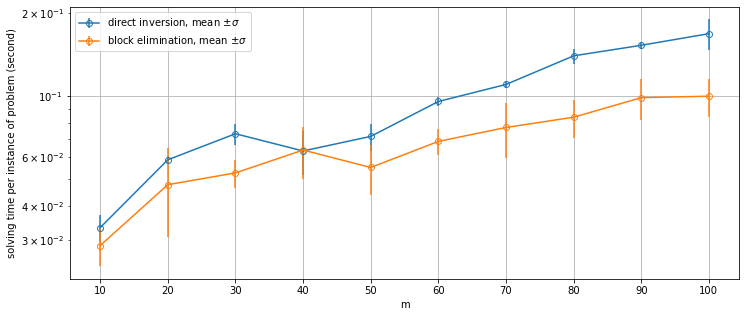

In [26]:
if __name__ == '__main__':
    plot_comparison(ms=[10 * i for i in range(1, 11)], n_dial=3)